# Продуктовая аналитика

**Трек А (командный)**

Датасеты:

*Brazilian E-Commerce Public Dataset by Olist*

*Marketing Funnel by Olist*

### Команда

| №   | Участник         | Пункты ТЗ | Задачи                                                                                            |
| --- | ---------------- | --------- | ------------------------------------------------------------------------------------------------- |
| 1   | Кошелева А. И.   | 3, 8, 9   | Сетап репозитория, метрик и их определений                                                        |
| 2   | Пасхальная Д. А. | 2, 6      | Проверка качества датасета, лицензии, объяснения почему подходит датасет, в 6 когортный retention |
| 3   | Ушинский Д. В.   | 4, 5      | Определение метрик и трекинга                                                                     |
| 4   | Иванова Т. Ю.    | 1, 7      | Описание продукта, этический чек-лист по ТЗ, валидация участника 3                                |
| 5   | Гайсин М. В.     | 2, 6      | Работа со 2 участником, в 6 LTV/CAC и метрики по выбору, по 2 валидация                           |

Связки - 2-5 участник, 3-4 участник

### Оглавление
1. Продукт
2. Данные
3. Определения
4. Метрики
5. Трекинг
6. Первые расчеты
7. Этика
8. Критерии успеха
9. Репозиторий

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path('data')
assert DATA_DIR.is_dir(), 'Запустите ноутбук из корня репозитория'
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', None)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

print('Папка с данными:', DATA_DIR)

Папка с данными: data


## 1. Продукт

### 1.1 Что делаем

Мы работаем как команда продуктовой аналитики Olist, бразильского e-commerce-сервиса и SaaS-экосистемы.

Olist позволяет малому и среднему бизнесу удобно управлять продажей своих товаров - создавать единый кабинет для управления листингами на всех крупнейших маркетплейсах с одного дашборда. Также в сервис интегрированы инструменты для автоматизации контроля остатков, отслеживания заказов, управления финансами и онлайн-оплаты, упрощенного создания сайтов и отправки заказов через партнерские компании.

 Мы анализируем платформу как двустороннюю площадку (покупатели и продавцы) и выстраиваем систему метрик для понимания точек роста и сильных мест компании.

Основной датасет описывает заказы, позиции, платежи, отзывы, покупателей и продавцов. Второй датасет (*Marketing Funnel*) описывает привлечение продавцов: лиды и закрытые сделки. Датасеты связаны по `seller_id`.


### 1.2 Для кого

| Сегмент | Описание | Цели                                                                                          |
|---|------------------------------------------------------------------------|-----------------------------------------------------------------------------------------------|
| Покупатели | Частные покупатели в Бразилии, которые заказывают товары онлайн | Получить заказ в обещанный срок, нужного качества                                             |
| Продавцы | Малый и средний бизнес, которому нужен канал продаж без собственной инфраструктуры | Получать заказы, не выстраивая свою логистику и платежную систему                             |
| Платформа | Команда Olist                                           | Растить число успешных заказов и удерживать покупателей и продавцов |

### 1.3 Какую проблему решает продукт

| Сегмент | Проблема пользователя                                                                                                                                                                                                                                          | Как продукт ее решает                                                                                                                               |
|---|----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|-----------------------------------------------------------------------------------------------------------------------------------------------------|
| Покупатели | Заказывать у незнакомого небольшого магазина рискованно: непонятно, придет ли товар, когда и в каком виде, к кому обращаться в случае проблем. У каждого магазина свои цены, сроки и условия оплаты. Нужно сравнивать множество сайтов без удобного интерфейса | Единая витрина, единые условия оплаты (в том числе в рассрочку) и доставки, отзывы других покупателей, известно кто отвечает за те или иные проблемы |
| Продавцы | У малого бизнеса нет собственного трафика, систем логистики и приема платежей, а выстраивать все это с нуля долго и дорого                                                                                                                                     | Простое подключение к платформе, где продавец размещает товары, а оплату и доставку обеспечивают платформа и ее партнеры               |

### 1.4 Гипотезы ценности

**Гипотеза ценности** - это проверяемое предположение о том, с какой реальной проблемой (или потребностью) сталкиваются пользователи и как именно ваш продукт или функция способны ее решить, принося им пользу

**H1. Покупатели.** Мы считаем, что покупатели, которые хотят купить у небольших магазинов, но опасаются ненадежности, получают от Olist ценность, когда заказ приходит в срок и соответствует ожиданиям. Это проявится в том, что большинство заказов будут доставлены до обещанной даты и получат оценку 4–5, а часть покупателей вернется за новым заказом.

**H2. Продавцы.** Мы считаем, что малый бизнес без собственного трафика и логистики получает от Olist ценность, когда после подключения к системе начинает получать заказы. Это проявится в том, что _большинство_ продавцов платформы сделают первые продажи за _разумный_ срок и продолжат продавать.

### 1.5 Бизнес-модель

Olist использует комбинированную схему получения дохода:
- Комиссия с продаж (Take Rate): платформа берет процент с каждой успешной транзакции
- SaaS-подписка: продавцы платят фиксированную ежемесячную или ежегодную плату за использование ERP-платформы и инструментов
- Партнерские сервисы: доход от предоставления рекламных инструментов внутри платформы, финансовых услуг и логистических сервисов

### 1.6 Репозиторий

Ноутбук лежит в репозитории: https://github.com/iverid/ProdAnal

## 2. Данные

**Аудит:** проверяем пропуски, дубли, ключи, диапазоны и хронологию. **Предобработка:** переводим даты в datetime, заменяем нулевой вес на NaN в рабочей копии, выбираем заказы для retention и объединяем таблицы. Исходные CSV не меняются.

*Подготовка данных, аудит и объединение: Пасхальная Д. А.; независимая валидация: Гайсин М. В.*

### 2.1 Источники и воспроизводимость

| Источник (автор — Olist) | Версия | Содержимое локальной выгрузки |
|---|---|---|
| [Brazilian E-Commerce Public Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) | 2, обновление 01.10.2021 | 8 CSV: заказы, покупатели, позиции, платежи, отзывы, товары, продавцы, перевод категорий |
| [Marketing Funnel by Olist](https://www.kaggle.com/datasets/olistbr/marketing-funnel-olist) | 2, обновление 16.11.2018 | 2 CSV: MQL и закрытые сделки |

Версии и лицензии сверены с [метаданными e-commerce](https://www.kaggle.com/api/v1/datasets/view/olistbr/brazilian-ecommerce) и [воронки](https://www.kaggle.com/api/v1/datasets/view/olistbr/marketing-funnel-olist).

Оба набора опубликованы под **CC BY-NC-SA 4.0**: требуется атрибуция, некоммерческое использование и та же лицензия для производных материалов. Текст лицензии — в `LICENSE.md`, атрибуция — в README. 


In [2]:
FILES = {
    'customers': 'Olist E-Commerce Public Dataset/olist_customers_dataset.csv',
    'orders': 'Olist E-Commerce Public Dataset/olist_orders_dataset.csv',
    'items': 'Olist E-Commerce Public Dataset/olist_order_items_dataset.csv',
    'payments': 'Olist E-Commerce Public Dataset/olist_order_payments_dataset.csv',
    'reviews': 'Olist E-Commerce Public Dataset/olist_order_reviews_dataset.csv',
    'products': 'Olist E-Commerce Public Dataset/olist_products_dataset.csv',
    'sellers': 'Olist E-Commerce Public Dataset/olist_sellers_dataset.csv',
    'categories': 'Olist E-Commerce Public Dataset/product_category_name_translation.csv',
    'mql': 'Marketing Funnel by Olist/olist_marketing_qualified_leads_dataset.csv',
    'deals': 'Marketing Funnel by Olist/olist_closed_deals_dataset.csv',
}
raw = {}
inventory = []
for name, relative_path in FILES.items():
    path = DATA_DIR / relative_path
    raw[name] = pd.read_csv(path, dtype={
        'customer_zip_code_prefix': 'string', 'seller_zip_code_prefix': 'string',
    })
    inventory.append({
        'table': name, 'rows': len(raw[name]), 'columns': len(raw[name].columns),
        'bytes': path.stat().st_size,
    })
inventory = pd.DataFrame(inventory).set_index('table')
display(inventory[['rows', 'columns']].rename(columns={'rows': 'Записи', 'columns': 'Поля'}))
print('Размер CSV, MiB:', round(inventory['bytes'].sum() / 1024**2, 2))


,Записи,Поля
table,,
customers,99441,5
orders,99441,8
items,112650,7
payments,103886,5
reviews,99224,7
products,32951,9
sellers,3095,4
categories,71,2
mql,8000,4


Размер CSV, MiB: 62.74



### 2.2 Пропуски и дубли

Сначала проверяем уникальность ключей. В `items` ключ составной: `(order_id, order_item_id)`, в платежах — `(order_id, payment_sequential)`. Повтор одного `order_id` здесь допустим. Повтор `customer_unique_id` сам по себе тоже не дубль: он связывает заказы одного покупателя.

In [3]:
KEYS = {
    'customers': ['customer_id'], 'orders': ['order_id'],
    'items': ['order_id', 'order_item_id'], 'payments': ['order_id', 'payment_sequential'],
    'reviews': ['review_id', 'order_id'], 'products': ['product_id'],
    'sellers': ['seller_id'], 'categories': ['product_category_name'],
    'mql': ['mql_id'], 'deals': ['mql_id'],
}
quality = pd.DataFrame(index=raw, columns=['Полные дубли', 'Повторы ключа', 'Пропуски ключа'])
for name, df in raw.items():
    quality.loc[name] = [df.duplicated().sum(), df.duplicated(KEYS[name]).sum(),
                         df[KEYS[name]].isna().any(axis=1).sum()]
assert quality.eq(0).all().all(), 'Появились дубли или пустые ключи — нужно правило обработки'
tables = {name: df.copy() for name, df in raw.items()}


**Решение по дублям:** строки сохраняем; дедупликация не требуется. Во всех 10 таблицах: 0 полных дублей, 0 конфликтов ключей, 0 пустых ключей. Теперь проверим поля с пропусками. Таблица ниже показывает только такие поля: процент считается от числа строк соответствующего файла.

In [4]:
missing_rows = []
for name, df in raw.items():
    for column in df.columns:
        count = int(df[column].isna().sum())
        if count > 0:
            missing_rows.append([name, column, count, round(count / len(df) * 100, 2)])
missingness = pd.DataFrame(missing_rows, columns=['Таблица', 'Поле', 'Пропуски', '% строк'])
display(missingness)

,Таблица,Поле,Пропуски,% строк
0,orders,order_approved_at,160,0.16
1,orders,order_delivered_carrier_date,1783,1.79
2,orders,order_delivered_customer_date,2965,2.98
3,reviews,review_comment_title,87656,88.34
4,reviews,review_comment_message,58247,58.70
5,products,product_category_name,610,1.85
6,products,product_name_lenght,610,1.85
7,products,product_description_lenght,610,1.85
8,products,product_photos_qty,610,1.85
9,products,product_weight_g,2,0.01


**Результат и решение:** у ключей покупателей и даты покупки пропусков нет — база retention от этих полей не сокращается. В отзывах нет 88.34% заголовков и 58.70% комментариев: это необязательный текст, заказы сохраняем. У 610 товаров нет категории; товар тоже сохраняем, категорию не угадываем.

В таблице сделок многие характеристики продавца заполнены менее чем на 10%; не используем их как обязательный фильтр. Пропуски дат доставки не заполняем: часть этапов могла не наступить.

### 2.3 Период, порядок событий и числовые аномалии

**Преобразование дат:** разбираем строки в datetime. Исходные значения доступны в `raw`; рабочие — в `tables`. Часовой пояс не приписываем, поскольку он не указан. Таблица показывает границы каждого события, а не общий период всех наборов.

In [5]:
DATE_COLUMNS = {
    'orders': ['order_purchase_timestamp', 'order_approved_at',
               'order_delivered_carrier_date', 'order_delivered_customer_date',
               'order_estimated_delivery_date'],
    'items': ['shipping_limit_date'],
    'reviews': ['review_creation_date', 'review_answer_timestamp'],
    'mql': ['first_contact_date'], 'deals': ['won_date'],
}
date_audit = []
for name, columns in DATE_COLUMNS.items():
    for col in columns:
        original = tables[name][col]
        parsed = pd.to_datetime(original, errors='coerce')
        invalid = int((original.notna() & parsed.isna()).sum())
        date_audit.append({'table': name, 'column': col, 'min': parsed.min(),
                           'max': parsed.max(), 'invalid': invalid, 'missing': int(parsed.isna().sum())})
        assert invalid == 0, (name, col, 'неразобранные даты')
        tables[name][col] = parsed
orders, items, payments = (tables[name] for name in ['orders', 'items', 'payments'])
customers, sellers, products = (tables[name] for name in ['customers', 'sellers', 'products'])
mql, deals = tables['mql'], tables['deals']
display(pd.DataFrame(date_audit).rename(columns={
    'table': 'Таблица', 'column': 'Поле', 'min': 'Начало', 'max': 'Конец',
    'invalid': 'Ошибки разбора', 'missing': 'Пропуски'}))

,Таблица,Поле,Начало,Конец,Ошибки разбора,Пропуски
0,orders,order_purchase_timestamp,2016-09-04 21:15:19,2018-10-17 17:30:18,0,0
1,orders,order_approved_at,2016-09-15 12:16:38,2018-09-03 17:40:06,0,160
2,orders,order_delivered_carrier_date,2016-10-08 10:34:01,2018-09-11 19:48:28,0,1783
3,orders,order_delivered_customer_date,2016-10-11 13:46:32,2018-10-17 13:22:46,0,2965
4,orders,order_estimated_delivery_date,2016-09-30 00:00:00,2018-11-12 00:00:00,0,0
5,items,shipping_limit_date,2016-09-19 00:15:34,2020-04-09 22:35:08,0,0
6,reviews,review_creation_date,2016-10-02 00:00:00,2018-08-31 00:00:00,0,0
7,reviews,review_answer_timestamp,2016-10-07 18:32:28,2018-10-29 12:27:35,0,0
8,mql,first_contact_date,2017-06-14 00:00:00,2018-05-31 00:00:00,0,0
9,deals,won_date,2017-12-05 02:00:00,2018-11-14 18:04:19,0,0


**Результат:** все непустые даты успешно разобраны. Покупки: 04.09.2016–17.10.2018; первые контакты MQL: 14.06.2017–31.05.2018; сделки: 05.12.2017–14.11.2018. Эти периоды различаются — поздние сделки нельзя оценивать по продажам за более раннее время.

Посмотрим на количество заказов по месяцам: это помогает выбрать рабочее окно и не спутать редкий хвост выгрузки с падением спроса.

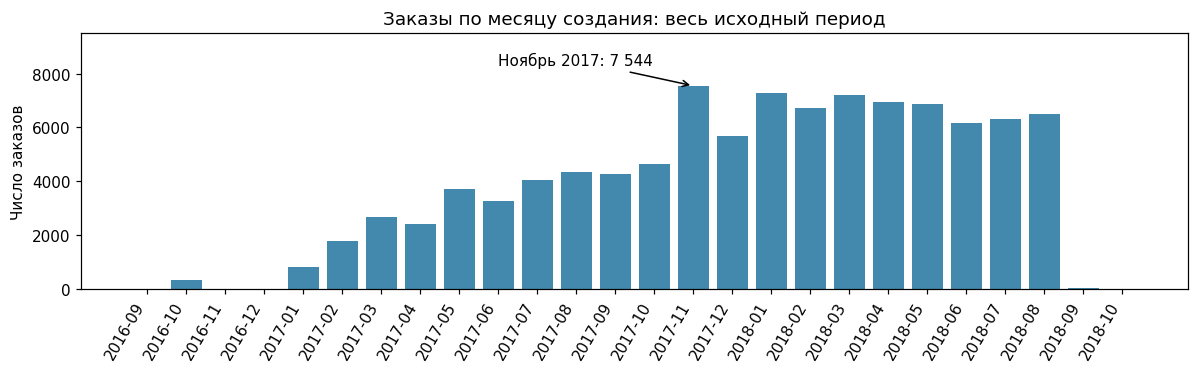

In [6]:
# Добавляем отсутствующие месяцы, чтобы был виден разрыв 2016 года.
purchase_month = orders.order_purchase_timestamp.dt.to_period('M')
months = pd.period_range(purchase_month.min(), purchase_month.max(), freq='M')
orders_by_month = orders.groupby(purchase_month).size().reindex(months, fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(range(len(months)), orders_by_month, color='#4388ad')
ax.set_xticks(range(len(months)), months.astype(str), rotation=60, ha='right')
ax.set(title='Заказы по месяцу создания: весь исходный период', ylabel='Число заказов')
peak = months.get_loc(pd.Period('2017-11', freq='M'))
ax.annotate('Ноябрь 2017: 7 544', xy=(peak, orders_by_month.iloc[peak]),
            xytext=(peak - 5, 8300), arrowprops={'arrowstyle': '->'})
ax.set_ylim(0, 9500)
fig.tight_layout()
plt.show()


**Интерпретация:** в 2016 году только 329 заказов, а в сентябре–октябре 2018 — 20; это границы покрытия, не доказательство низкой активности продукта. Основной анализ ограничиваем январем 2017 — августом 2018. Первая покупка ищется с сохранением предыстории 2016 года. Конец августа тоже может быть усечен: полнота выборки автором не гарантирована.

В ноябре 2017 — 7 544 заказа против 4 631 в октябре (рост около 63%). Всплеск может быть связан с Black Friday и сезонностью; по одним заказам причину доказать нельзя. Наблюдения сохраняем, сезонный пик не объявляем выбросом.

**Хронология:** проверяем невозможный порядок событий. Правило обработки задаем отдельно для логистики и retention: ошибочный интервал доставки не делает автоматически ошибочной дату покупки.

In [7]:
deal_dates = deals.merge(mql[['mql_id', 'first_contact_date']], on='mql_id', validate='one_to_one')
time_checks = {
    'approval_before_purchase': orders.order_approved_at.lt(orders.order_purchase_timestamp).sum(),
    'carrier_before_purchase': orders.order_delivered_carrier_date.lt(orders.order_purchase_timestamp).sum(),
    'delivery_before_purchase': orders.order_delivered_customer_date.lt(orders.order_purchase_timestamp).sum(),
    'delivery_before_carrier': orders.order_delivered_customer_date.lt(orders.order_delivered_carrier_date).sum(),
    'delivered_without_delivery_date': (orders.order_status.eq('delivered') & orders.order_delivered_customer_date.isna()).sum(),
    'shipping_limit_from_2019': items.shipping_limit_date.ge('2019-01-01').sum(),
    'deal_before_first_contact': deal_dates.won_date.lt(deal_dates.first_contact_date).sum(),
}
display(pd.Series(time_checks, name='Число строк').rename(index={
    'approval_before_purchase': 'Оплата одобрена до покупки',
    'carrier_before_purchase': 'Передача перевозчику до покупки',
    'delivery_before_purchase': 'Доставка до покупки',
    'delivery_before_carrier': 'Доставка до передачи перевозчику',
    'delivered_without_delivery_date': 'Delivered без даты доставки',
    'shipping_limit_from_2019': 'Дедлайн отправки в 2019+ году',
    'deal_before_first_contact': 'Сделка до первого контакта',
}).to_frame())

,Число строк
Оплата одобрена до покупки,0
Передача перевозчику до покупки,166
Доставка до покупки,0
Доставка до передачи перевозчику,23
Delivered без даты доставки,8
Дедлайн отправки в 2019+ году,4
Сделка до первого контакта,1


**Решения по времени:**
- 166 передач до покупки и 23 доставки до передачи: для retention строки сохраняем, поскольку дата покупки корректна. При расчете длительности логистических этапов такие интервалы нужно исключить. Счетчики могут пересекаться.
- 8 заказов `delivered` без даты доставки: длительность неизвестна, но статус и дата покупки позволяют оставить их в retention.
- 4 дедлайна отправки в 2020 году: не используем эти значения для оценки сроков; retention от дедлайна не зависит.
- 1 сделка до первого контакта: сохраняем в общем числе сделок; для анализа длительности воронки такой интервал непригоден.

**Числа и выбросы.** Ниже — диапазоны и нулевые значения значимых полей. Цены скошены, поэтому большие значения не удаляем только по статистическому порогу. Заявленная выручка в основном нулевая; ее нельзя использовать для оценки дохода Olist.

In [8]:
numeric_columns = {
    'items': ['price', 'freight_value'],
    'payments': ['payment_value', 'payment_installments'],
    'products': ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm'],
    'reviews': ['review_score'],
    'deals': ['declared_monthly_revenue', 'declared_product_catalog_size'],
}
numeric_audit = []
for name, columns in numeric_columns.items():
    for col in columns:
        s = raw[name][col]  
        numeric_audit.append({
            'table': name, 'column': col, 'min': s.min(), 'median': s.median(),
            'p99': s.quantile(0.99), 'max': s.max(), 'negative': int(s.lt(0).sum()),
            'zero': int(s.eq(0).sum()),
        })
numeric_audit = pd.DataFrame(numeric_audit)
display(numeric_audit.rename(columns={
    'table': 'Таблица', 'column': 'Поле', 'min': 'Мин.', 'median': 'Медиана',
    'p99': '99-й процентиль', 'max': 'Макс.', 'negative': 'Отрицательные', 'zero': 'Нули'}))
assert tables['reviews'].review_score.between(1, 5).all()
products['weight_invalid'] = raw['products'].product_weight_g.le(0)
products['product_weight_g'] = products.product_weight_g.mask(products.weight_invalid)

,Таблица,Поле,Мин.,Медиана,99-й процентиль,Макс.,Отрицательные,Нули
0,items,price,0.85,74.99,890.0000,6735.00,0,0
1,items,freight_value,0.00,16.26,84.5200,409.68,0,383
2,payments,payment_value,0.00,100.00,1039.9165,13664.08,0,9
3,payments,payment_installments,0.00,1.00,10.0000,24.00,0,2
4,products,product_weight_g,0.00,700.00,22538.0000,40425.00,0,4
5,products,product_length_cm,7.00,25.00,100.0000,105.00,0,0
6,products,product_height_cm,2.00,13.00,69.0000,105.00,0,0
7,products,product_width_cm,6.00,20.00,63.0000,118.00,0,0
8,reviews,review_score,1.00,5.00,5.0000,5.00,0,0
9,deals,declared_monthly_revenue,0.00,0.00,191800.0000,50000000.00,0,797


### 2.4 Решения по качеству и предобработка

**Решения по числам:**

| Наблюдение | Решение | Влияние на retention |
|---|---|---|
| Заявленная месячная выручка: 797 нулей из 842, медиана 0, максимум 50 млн BRL | Исходное значение сохраняем; не используем как доход Olist или LTV, нули не трактуем как доказанную нулевую выручку | Нет: поле не входит в формулу |
| Вес 0 г у 4 товаров | В рабочей копии заменен на NaN, добавлен флаг `weight_invalid`; товары и заказы сохранены | Нет |
| 9 строк платежей с суммой 0 | Сначала суммируем все платежи заказа и проверяем его итог; не удаляем заказ по одной строке | База не фильтруется по платежам |
| Дорогие товары: максимум 6 735 BRL | Сохраняем: цена не является доказанной ошибкой; для денежных средних нужен анализ чувствительности | Нет |
| Бесплатная доставка | Допустимое значение, сохраняем | Нет |

**Тестовые аккаунты:** полей `is_test`, email и достоверного списка аккаунтов нет. Проверяем ID на пустоту и формат 32 шестнадцатеричных символов. Корректный формат не доказывает реальность пользователя; тестовый фильтр не применяем.

**Переходим к предобработке для retention.** Учитываем заказы со статусом `delivered`, с валидной датой покупки и известным `customer_unique_id`. Активность датируем созданием заказа, а не доставкой. Это ретроспективный анализ по финальному статусу: он не показывает статус заказа в момент покупки.

Отчетное окно — 01.01.2017–31.08.2018, исключающая правая граница — 01.09.2018. Для поиска первой покупки сохраняем всю предысторию до этой границы: покупателя из 2016 года нельзя сделать новым в 2017.

In [9]:
identifier_checks = pd.DataFrame([
    {'table': name, 'column': col,
     'missing': int(df[col].isna().sum()),
     'invalid_format': int((df[col].notna() & ~df[col].astype('string').str.fullmatch(r'[0-9a-f]{32}', na=False)).sum())}
    for name, df in tables.items()
    for col in ['customer_id', 'customer_unique_id', 'seller_id', 'mql_id'] if col in df
])
assert identifier_checks[['missing', 'invalid_format']].eq(0).all().all()
print('Пустых или некорректных ID не найдено. По этим полям тестовые аккаунты не определяются.')

Пустых или некорректных ID не найдено. По этим полям тестовые аккаунты не определяются.


**Выбор базы заказов.** Присоединяем устойчивый ID покупателя, оставляем успешно доставленные заказы до конца окна. История 2016 года нужна для первой покупки; отчетные заказы начинаются с 2017 года. Числа ниже показывают последовательность отбора, а не независимые причины удаления.

In [10]:
ANALYSIS_START = pd.Timestamp('2017-01-01')
ANALYSIS_END = pd.Timestamp('2018-09-01')  
LAST_OBSERVED_DAY = ANALYSIS_END - pd.Timedelta(days=1)
order_customers = orders.merge(
    customers[['customer_id', 'customer_unique_id']], on='customer_id', how='left', validate='one_to_one',
)
assert order_customers.customer_unique_id.notna().all()
valid_activity = (order_customers.order_status.eq('delivered') &
                  order_customers.order_purchase_timestamp.notna() &
                  order_customers.customer_unique_id.notna())
purchase_history = order_customers.loc[
    valid_activity & order_customers.order_purchase_timestamp.lt(ANALYSIS_END)
].copy()
purchase_history['purchase_date'] = purchase_history.order_purchase_timestamp.dt.normalize()
analysis_orders = purchase_history.loc[purchase_history.purchase_date.ge(ANALYSIS_START)].copy()
display(pd.Series({
    'Все исходные заказы': len(orders),
    'Исключено: статус не delivered': int((~orders.order_status.eq('delivered')).sum()),
    'Сохранено в предыстории: delivered до 2017': int(purchase_history.purchase_date.lt(ANALYSIS_START).sum()),
    'Delivered в отчетном окне': len(analysis_orders),
    'Покупателей с delivered в окне': analysis_orders.customer_unique_id.nunique(),
}, name='Количество').to_frame())

,Количество
Все исходные заказы,99441
Исключено: статус не delivered,2963
Сохранено в предыстории: delivered до 2017,267
Delivered в отчетном окне,96211
Покупателей с delivered в окне,93104


**Получили:** 96 211 заказов и 93 104 активных покупателя в окне. Еще 267 доставленных заказов до 2017 года сохраняются в истории. В разделе 6 из отчетных когорт будут исключены 10 покупателей, чья первая покупка была до 2017 года. Число новых покупателей когорт — 93 094.

**Проверка нулевых платежей.** В одном заказе может быть несколько платежей. Суммируем их по `order_id`, чтобы отличить нулевую строку от нулевой оплаты всего заказа.

In [11]:
payment_totals = payments.groupby('order_id').payment_value.sum()
zero_payment_order_ids = payments.loc[payments.payment_value.eq(0), 'order_id'].unique()
zero_payment_check = payment_totals.loc[zero_payment_order_ids]
print('Нулевых строк платежей:', int(payments.payment_value.eq(0).sum()))
print('Заказов с такими строками:', len(zero_payment_check))
print('Из них с положительной общей оплатой:', int(zero_payment_check.gt(0).sum()))
print('Из них с нулевой общей оплатой:', int(zero_payment_check.eq(0).sum()))

Нулевых строк платежей: 9
Заказов с такими строками: 8
Из них с положительной общей оплатой: 5
Из них с нулевой общей оплатой: 3


**Результат проверки платежей:** 9 нулевых строк относятся к 8 заказам. У 5 из них общая оплата положительна, у 3 — равна нулю. Нулевая строка поэтому не означает автоматически нулевую сумму заказа.

**Решение:** строки и заказы сохраняем. Нулевой платеж не доказывает тестовость заказа, а итоговую сумму считаем по всем его платежам.

### 2.5 Объединение с воронкой

Связываем MQL со сделками по `mql_id`, затем позиции со сделками по `seller_id`. Funnel относится к привлечению продавцов, не покупателей. Левые соединения сохраняют все заявки и позиции; проверяем ключи, число строк и сумму цен.

In [12]:
assert deals.seller_id.is_unique, 'Нужно согласовать правило атрибуции нескольких MQL продавцу'
assert deals.mql_id.isin(mql.mql_id).all(), 'У сделки нет исходного MQL'
funnel = mql.merge(deals, on='mql_id', how='left', validate='one_to_one')
deal_mql = deals.merge(mql, on='mql_id', how='left', validate='one_to_one')
items_with_funnel = items.merge(deal_mql, on='seller_id', how='left', validate='many_to_one').merge(
    orders[['order_id', 'order_purchase_timestamp', 'order_status']],
    on='order_id', how='left', validate='many_to_one',
)
items_with_funnel['funnel_known_at_purchase'] = (
    items_with_funnel.won_date.notna() &
    items_with_funnel.won_date.le(items_with_funnel.order_purchase_timestamp)
)
assert len(funnel) == len(mql)
assert len(items_with_funnel) == len(items)
assert items_with_funnel.order_purchase_timestamp.notna().all(), 'У позиции нет даты заказа'
assert np.isclose(items_with_funnel.price.sum(), items.price.sum())
print('Сохранены все 8 000 MQL и 112 650 позиций; сумма цен после join не изменилась.')

Сохранены все 8 000 MQL и 112 650 позиций; сумма цен после join не изменилась.


**Охват: два разных знаменателя.** Первая доля описывает пересечение исходных файлов за весь период. Вторая показывает охват в сопоставимом окне: декабрь 2017 — август 2018, то есть с месяца первых сделок до конца анализа. Числитель второй доли включает только позиции, купленные после сделки соответствующего продавца. Это охват выборки, а не конверсия всей платформы.

In [13]:
matched_sellers = int(sellers.seller_id.isin(deals.seller_id).sum())
matched_items = items_with_funnel.mql_id.notna()
FUNNEL_WINDOW_START = deals.won_date.min().to_period('M').start_time
in_funnel_window = (items_with_funnel.order_purchase_timestamp.ge(FUNNEL_WINDOW_START) &
                    items_with_funnel.order_purchase_timestamp.lt(ANALYSIS_END))
window_matches = in_funnel_window & items_with_funnel.funnel_known_at_purchase
coverage = pd.DataFrame([
    ('MQL с закрытой сделкой', int(funnel.seller_id.notna().sum()), len(funnel)),
    ('Продавцы e-commerce с MQL', matched_sellers, len(sellers)),
    ('Сделки с продавцом в e-commerce', matched_sellers, len(deals)),
    ('Позиции с MQL: весь исходный период', int(matched_items.sum()), len(items)),
    ('Позиции с MQL: декабрь 2017 — август 2018', int(window_matches.sum()), int(in_funnel_window.sum())),
], columns=['coverage', 'matched', 'base']).set_index('coverage')
coverage['pct'] = (coverage.matched / coverage.base * 100).round(2)
display(coverage.rename(columns={'matched': 'Найдено', 'base': 'База', 'pct': '%'}))
print('Связанных позиций с покупкой до сделки:',
      int((matched_items & ~items_with_funnel.funnel_known_at_purchase).sum()))
eligible_deals = deals.loc[deals.won_date.lt(ANALYSIS_END)].copy()
eligible_deals['followup_days'] = (LAST_OBSERVED_DAY - eligible_deals.won_date.dt.normalize()).dt.days
print('Сделок после конца анализа:', int(deals.won_date.ge(ANALYSIS_END).sum()))
print('Доступное наблюдение после сделки, дни: мин. / медиана / макс.:',
      eligible_deals.followup_days.min(), eligible_deals.followup_days.median(), eligible_deals.followup_days.max())

,Найдено,База,%
coverage,,,
MQL с закрытой сделкой,842,8000,10.52
Продавцы e-commerce с MQL,380,3095,12.28
Сделки с продавцом в e-commerce,380,842,45.13
Позиции с MQL: весь исходный период,5044,112650,4.48
Позиции с MQL: декабрь 2017 — август 2018,5044,67723,7.45


Связанных позиций с покупкой до сделки: 0
Сделок после конца анализа: 50
Доступное наблюдение после сделки, дни: мин. / медиана / макс.: 1 142.0 269


**Вывод по объединению:** в сопоставимом окне охват позиций составляет **5044 / 67 723 = 7.45%**, тогда как 4.48% относится ко всему исходному периоду. Смешивать эти знаменатели нельзя. Связанных покупок до сделки не найдено. У 792 сделок до конца окна доступно от 1 до 269 дней наблюдения, медиана — 142 дня; остальные 50 сделок произошли позже.

### 2.6 Вывод

Основной набор подходит для анализа повторных успешных покупок: есть устойчивый customer_unique_id, время создания, статусы и история заказов. Позиции, платежи и доставка позволяют диагностировать качество выполнения заказа. Funnel добавляет канал и дату привлечения части продавцов, но не описывает путь покупателя от визита до покупки.

Ограничения: это анонимизированная историческая выборка; первая наблюдаемая покупка может не быть первой в жизни. Нет сессий, затрат на привлечение, комиссии, маржи, подписок и полных возвратов — фактические CAC и LTV платформы не идентифицируются. 

**Предобработка:** даты переведены в datetime; 4 нулевых веса заменены на NaN в рабочей копии; таблицы объединены по ключам. Для retention подготовлены `purchase_history` с предысторией и `analysis_orders` с заказами отчетного окна. Заказы отбираются по статусу и периоду, а не по цене, весу или наличию отзыва.

**Для LTV/CAC продавцов:** 380 связанных продавцов — пересечение выборок, а не полная база привлеченных. Наблюдение после сделки короче 9 месяцев, у поздних продавцов — еще меньше. Сумма продаж за это окно — усеченный GMV, не пожизненная ценность и не доход платформы. Отсутствие продавца в e-commerce не доказывает нулевые продажи.

| Переменная | Содержимое |
|---|---|
| `raw` | Словарь исходных таблиц без предобработки. |
| `tables` | Словарь рабочих таблиц с преобразованными датами и исправленным нулевым весом. `orders`, `customers`, `items`, `payments`, `products`, `sellers`, `mql`, `deals` ссылаются на соответствующие таблицы этого словаря. |
| `order_customers` | Все заказы с присоединенным `customer_unique_id`, без фильтра статуса и периода. |
| `purchase_history` | Заказы `delivered`, созданные до 01.09.2018, с `customer_unique_id` и календарной датой `purchase_date`; предыстория 2016 года сохранена. |
| `analysis_orders` | Заказы из `purchase_history` за 01.01.2017–31.08.2018. |
| `funnel` | Все MQL с присоединенными сделками по `mql_id`; заявки без сделки сохранены. |
| `items_with_funnel` | Все позиции заказов с данными воронки по `seller_id`, датой и статусом заказа. Фильтр `delivered` и отчетное окно не применены; `funnel_known_at_purchase` указывает, заключена ли сделка не позже покупки. |
| `payment_totals` | Series с суммой всех платежей по каждому `order_id`, без фильтра статуса и периода. |

## 3. Определения

### 3.1 Активный пользователь

В данных нет входов и сессий. Единственное подтвержденное действие пользователя - заказ, соответственно активность будет вычисляться через заказы

- Активный покупатель за период - покупатель, у которого в периоде есть хотя бы один учитываемый заказ
- Активный продавец за период - продавец, у которого в периоде есть хотя бы одна позиция в учитываемом заказе (сделан 1 заказ)
- Период - день (DAU), неделя (WAU) или календарный месяц (MAU)

### 3.2 Конверсия

В проекте три конверсии:

- Заказ - доставка: заказы со статусом delivered / все учитываемые заказы периода создания
- Лид - закрытая сделка: лиды с закрытой сделкой / все лиды
- Контракт с продавцом - активный продавец: активные продавцы (первый заказ в течение 90 дней после заключения контракта) / все закрытые сделки

### 3.3 Удержание
- Первый заказ покупателя - самый ранний учитываемый заказ
- Повторный заказ - учитываемый заказ, созданный в более позднюю календарную дату, чем первый. Заказы того же дня считаются частью первой покупки (разбивка одной покупки на несколько)
- Удержание за N дней - доля покупателей, у которых есть хотя бы один повторный заказ в течение N дней после даты первого. Основной горизонт - 90 дней; дополнительно 30, 60 и 180 дней

### 3.4 Когорта
- Когорта покупателей - выполняется по календарному месяцу первого учитываемого заказа
- Когорта продавцов - выполняется по календарному месяцу заключения контракта с платформой

### 3.5 Правило оттока
Покупатель ушел, если с даты его последнего учитываемого заказа прошло 180 дней без нового заказа. Продавец ушел, если с даты его последнего заказа прошло 90 дней без нового.

180 дней - самый длинный горизонт возврата покупателей; 90 дней - окно активации и LTV продавцов.


## 4. Метрики

### 4.1 Пирамида метрик

| Уровень | Метрика | Формула |
|---|---|---|
| North Star | Успешные сделки в месяц | заказы месяца со статусом `delivered`, доставленные не позже `order_estimated_delivery_date` и получившие оценку 4–5 |
| Диагностическая | Повторные покупки за 90 дней | покупатели с повторным заказом в течение 90 дней после первого / все покупатели с первым заказом в том же месяце |
| Диагностическая | Активация продавцов за 90 дней | продавцы с первой продажей в течение 90 дней после подписания контракта (`won_date`) / все продавцы, подписавшие контракт в том же месяце |
| Риск | Доля отмененных заказов | заказы со статусом `canceled` или `unavailable` / все заказы месяца |

Успешные сделки = покупатели × заказов на покупателя × доля успешных заказов. Активация продавцов отвечает за ассортимент, который приводит покупателей, повторные покупки — за число заказов на покупателя. Доля отмененных заказов следит, чтобы успешные сделки не росли за счет сорванных.

### 4.2 Успешные сделки в месяц

**Зачем:** показывает, сколько раз платформа выполнила обещание обеим сторонам: покупатель вовремя получил заказ и доволен, продавец получил оплаченную продажу. Комиссия Olist берется с успешных сделок, поэтому метрика связана с выручкой.

**Решение:** какие инициативы брать в работу — приоритет у тех, что увеличивают число успешных сделок. Также это итоговый критерий A/B-тестов.

### 4.3 Повторные покупки за 90 дней

**Зачем:** показывает, возвращаются ли покупатели. Без повторных покупок каждый заказ требует нового привлечения, а от удержания зависит LTV.

**Решение:** запускать ли программы возврата (промокод на второй заказ, рассылки) и сколько можно тратить на привлечение одного покупателя.

### 4.4 Активация продавцов за 90 дней

**Зачем:** показывает, начинают ли подключенные продавцы продавать. Контракт без продаж — это деньги на привлечение продавца без отдачи.

**Решение:** на какие сегменты и каналы лидов направлять отдел продаж и нужен ли онбординг для новых продавцов.

### 4.5 Доля отмененных заказов

**Зачем:** успешные сделки можно растить объемом — акциями или подключением непроверенных продавцов, — и тогда растет доля сорванных сделок. Эта метрика ловит такой эффект.

**Решение:** порог задается заранее, и изменение, которое увеличило число успешных сделок, но вывело долю отмен за порог, не внедряется. Продавцы, у которых часто нет товара в наличии (`unavailable`), получают ограничения.

## 5. Трекинг

В датасете нет лога событий. В таблице перечислены события, которые нужны для метрик из разд. 4, и поля датасета, из которых они восстанавливаются.

У каждого события есть общие поля: кто сделал (`customer_unique_id`, `seller_id` или `mql_id`), что сделал (имя события) и когда (`event_ts` в UTC), а также уникальный `event_id`, по которому отбрасываются дубли. События отправляет сервер после успешной операции. Сорванный заказ фиксируется отдельным событием `order_canceled`.

| Событие | Триггер | Параметры | Метрика | Этап пути | Поле датасета |
|---|---|---|---|---|---|
| `lead_created` | Продавец оставил заявку | `mql_id`, `event_ts`, `origin` | Конверсия «лид → закрытая сделка» | Продавец: привлечение | `marketing_qualified_leads`: `mql_id`, `first_contact_date`, `origin` |
| `deal_won` | Подписан контракт с продавцом | `seller_id`, `event_ts`, `business_segment` | Активация продавцов | Продавец: подключение | `closed_deals`: `seller_id`, `won_date`, `business_segment` |
| `order_placed` | Покупатель оформил заказ | `customer_unique_id`, `event_ts`, `order_id`, `seller_id` | Успешные сделки, повторные покупки, активация продавцов, доля отмененных заказов | Покупатель: покупка | `customers.customer_unique_id`, `orders`: `order_purchase_timestamp`, `order_id`; `order_items.seller_id` |
| `order_delivered` | Заказ вручен покупателю | `customer_unique_id`, `event_ts`, `order_id`, `estimated_date` | Успешные сделки | Покупатель: получение | `customers.customer_unique_id`, `orders`: `order_delivered_customer_date`, `order_id`, `order_estimated_delivery_date` |
| `order_canceled` | Заказ отменен или товара нет в наличии | `customer_unique_id`, `event_ts`, `order_id`, `status` | Доля отмененных заказов | Покупатель: отмена | `customers.customer_unique_id`, `orders`: `order_id`, `order_status` (`canceled`, `unavailable`); времени отмены в датасете нет |
| `review_submitted` | Покупатель поставил оценку | `customer_unique_id`, `event_ts`, `order_id`, `review_score` | Успешные сделки | Покупатель: оценка | `customers.customer_unique_id`, `order_reviews`: `review_answer_timestamp`, `order_id`, `review_score` |

## 6. Первые расчеты


*Когортный retention: Пасхальная Д. А. LTV/CAC и дополнительные метрики: Гайсин М. В.*

### 6.1 Когортный retention покупателей по календарным месяцам

**Правила расчета:** покупатель — `customer_unique_id`, активность — создание заказа, который в выгрузке имеет финальный статус `delivered`. Первая покупка определяется по всей доступной истории до 01.09.2018; отчетные когорты — месяцы первой покупки с января 2017 по август 2018. Повторы в день первой покупки не считаются возвратом.

**M1, M2, …** — доля покупателей когорты с покупкой именно в соответствующем календарном месяце после месяца первой покупки. Знаменатель — вся когорта, покупатель учитывается один раз за месяц. M0 = 100% обозначает формирование когорты.

Например: покупка 1 января и повтор 31 января попадут в R30, но не в M1; повтор 1 февраля попадет в M1, хотя это уже 31-й день. Поэтому M1 и R30 не должны совпадать. Сначала определим когорты, затем посчитаем активность.

In [14]:
first_purchase = purchase_history.groupby('customer_unique_id')['purchase_date'].min().rename('first_purchase_date')
buyer_cohorts = first_purchase.to_frame()
buyer_cohorts['cohort'] = buyer_cohorts.first_purchase_date.dt.to_period('M')
buyer_cohorts = buyer_cohorts.loc[buyer_cohorts.first_purchase_date.ge(ANALYSIS_START)].copy()
cohort_index = pd.period_range(ANALYSIS_START, LAST_OBSERVED_DAY, freq='M')
cohort_sizes = buyer_cohorts.groupby('cohort').size().reindex(cohort_index, fill_value=0).rename('buyers')
cohort_sizes.index.name = 'cohort'
print('Новых покупателей в отчетных когортах:', int(cohort_sizes.sum()))
print('Когорт:', len(cohort_sizes))

Новых покупателей в отчетных когортах: 93094
Когорт: 20


**База:** 93 094 новых покупателя, 20 месячных когорт. У 10 других покупателей первая покупка была до 2017 года — они остаются в истории, но не попадают в эти когорты. Теперь каждую покупку связываем с когортой и вычисляем возраст в днях и календарных месяцах.

In [15]:
buyer_activity = purchase_history.merge(
    buyer_cohorts, left_on='customer_unique_id', right_index=True, how='inner', validate='many_to_one',
)
buyer_activity['age_days'] = (buyer_activity.purchase_date - buyer_activity.first_purchase_date).dt.days
buyer_activity['activity_month'] = buyer_activity.purchase_date.dt.to_period('M')
buyer_activity['month_age'] = (
    buyer_activity.activity_month.astype('int64') - buyer_activity.cohort.astype('int64')
)
repeats = buyer_activity.loc[buyer_activity.age_days.gt(0)].copy()
assert buyer_cohorts.index.is_unique
assert buyer_activity.age_days.ge(0).all()
assert repeats.age_days.gt(0).all()

**Матрица удержания:** считаем уникальных покупателей в каждой паре «когорта — месяц жизни». Наблюдаемый месяц без возвратов заполняем 0, еще не наступивший месяц — NaN. Это различие важно: отсутствие наблюдения нельзя считать оттоком.

In [16]:
month_ages = pd.Index(range(len(cohort_index)), name='month_age')
monthly_counts = repeats.groupby(['cohort', 'month_age']).customer_unique_id.nunique().unstack(
    'month_age', fill_value=0,
).reindex(index=cohort_index, columns=month_ages, fill_value=0)
monthly_counts[0] = cohort_sizes  # M0 — приобретение, а не повтор
observed_months = pd.DataFrame(
    [[cohort + int(k) <= LAST_OBSERVED_DAY.to_period('M') for k in month_ages] for cohort in cohort_index],
    index=cohort_index, columns=month_ages,
)
monthly_counts = monthly_counts.where(observed_months & cohort_sizes.gt(0).to_numpy()[:, None])
monthly_retention = monthly_counts.div(cohort_sizes.replace(0, np.nan), axis=0)
assert monthly_retention[0].eq(1).all()
assert monthly_retention.stack().dropna().between(0, 1).all()
assert monthly_counts.where(~observed_months).isna().all().all()
m1_mature = observed_months[1] & cohort_sizes.gt(0)
m1_buyers = int(cohort_sizes.loc[m1_mature].sum())
m1_returned = int(monthly_counts.loc[m1_mature, 1].sum())
print(f'M1: {m1_returned} / {m1_buyers} = {m1_returned / m1_buyers * 100:.3f}%')

M1: 420 / 86950 = 0.483%


**Heatmap:** строки — месяцы первой покупки, `n` — размер когорты; столбцы — M1–M12; значения — проценты вернувшихся. Серый фон и «—» означают отсутствие полного календарного месяца наблюдения. 

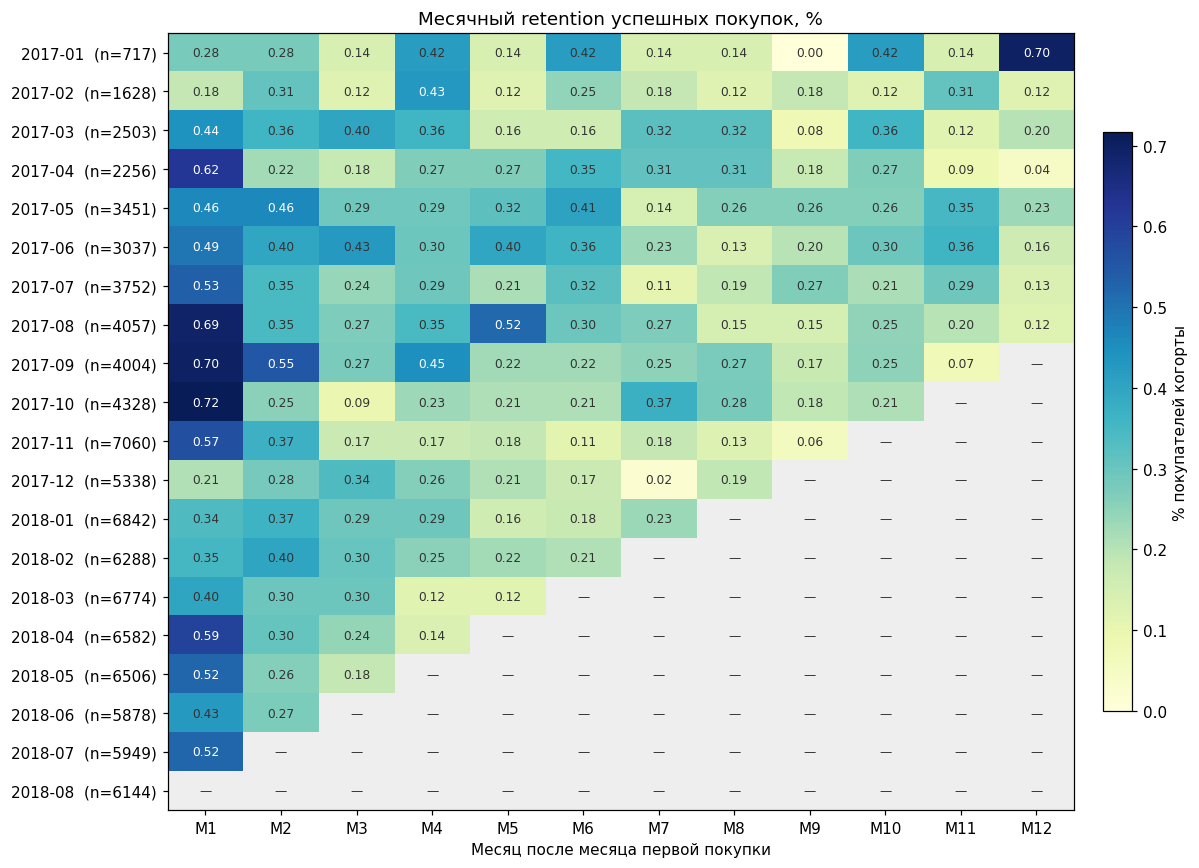

In [17]:
heatmap = monthly_retention.loc[:, 1:12].mul(100)
colors = plt.get_cmap('YlGnBu').copy()
colors.set_bad('#eeeeee')
fig, ax = plt.subplots(figsize=(11, 8))
image = ax.imshow(np.ma.masked_invalid(heatmap.to_numpy()), aspect='auto',
                  cmap=colors, vmin=0, vmax=np.nanmax(heatmap.to_numpy()))
ax.set_xticks(range(12), [f'M{k}' for k in range(1, 13)])
ax.set_yticks(range(len(cohort_index)),
              [f'{cohort}  (n={cohort_sizes.loc[cohort]})' for cohort in cohort_index])
for row in range(len(heatmap)):
    for column in range(len(heatmap.columns)):
        value = heatmap.iloc[row, column]
        label = '—' if pd.isna(value) else f'{value:.2f}'
        ink = 'white' if pd.notna(value) and value > image.norm.vmax * 0.6 else '#333333'
        ax.text(column, row, label, ha='center', va='center', fontsize=8, color=ink)
ax.set(title='Месячный retention успешных покупок, %', xlabel='Месяц после месяца первой покупки')
fig.colorbar(image, ax=ax, label='% покупателей когорты', fraction=0.03, pad=0.03)
fig.tight_layout()
plt.show()

**Вывод по календарному удержанию:** в следующий месяц возвращается менее 1% покупателей каждой когорты. Общий M1 по 19 полностью наблюдаемым когортам — 420 / 86 950 = 0.483%. Небольшие колебания процентов могут означать всего несколько покупателей; по heatmap нельзя доказать тренд улучшения.

### 6.2 Возврат в течение 30, 60, 90 и 180 дней

R_H — доля покупателей хотя бы с одной повторной покупкой на дне `1 ≤ d ≤ H` после первой. Возврат внутри месяца первой покупки учитывается.

Включаем когорту только если последний день ее месяца + H дней не позже 31.08.2018. Так не выбираем только ранних покупателей частично наблюдаемого месяца. Таблица по когортам показывает, какие горизонты доступны; «—» не означает 0.

In [18]:
first_repeat_age = repeats.groupby('customer_unique_id').age_days.min()
buyer_cohorts['first_repeat_age'] = first_repeat_age
HORIZONS = (30, 60, 90, 180)
horizon_counts = pd.DataFrame(index=cohort_index)
horizon_observed = pd.DataFrame(index=cohort_index)
for horizon in HORIZONS:
    mature = cohort_index.to_timestamp(how='end').normalize() + pd.Timedelta(days=horizon) <= LAST_OBSERVED_DAY
    returned = buyer_cohorts.loc[buyer_cohorts.first_repeat_age.between(1, horizon)].groupby('cohort').size()
    horizon_counts[horizon] = returned.reindex(cohort_index, fill_value=0).where(mature & cohort_sizes.gt(0))
    horizon_observed[horizon] = mature & cohort_sizes.gt(0)
horizon_retention = horizon_counts.div(cohort_sizes.replace(0, np.nan), axis=0)
horizon_table = pd.DataFrame({'Покупателей': cohort_sizes})
for horizon in HORIZONS:
    horizon_table[f'R{horizon}, %'] = horizon_retention[horizon].mul(100).round(2)
display(horizon_table.astype(object).fillna('—'))
assert horizon_retention.stack().dropna().between(0, 1).all()
assert horizon_counts.where(~horizon_observed).isna().all().all()

,Покупателей,"R30, %","R60, %","R90, %","R180, %"
cohort,,,,,
2017-01,717,0.56,0.84,0.84,1.67
2017-02,1628,0.61,0.74,0.92,1.66
2017-03,2503,0.48,0.76,1.28,1.8
2017-04,2256,0.71,1.06,1.33,1.99
2017-05,3451,0.9,1.25,1.59,2.35
2017-06,3037,0.56,0.99,1.42,2.3
2017-07,3752,0.77,1.12,1.31,2.05
2017-08,4057,0.62,1.23,1.43,2.46
2017-09,4004,0.92,1.37,1.82,2.55


**Результат:** для R90 полностью наблюдаемы 17 когорт до мая 2018, для R180 — 14 когорт до февраля 2018. Для сравнения R30/R60/R90 фиксируем общую 90-дневную базу. Доли считаем как сумму вернувшихся, деленную на сумму покупателей этих когорт, а не как простое среднее процентов.

In [19]:
common_mature = horizon_observed[90]
common_base = int(cohort_sizes.loc[common_mature].sum())
common_horizon_summary = pd.DataFrame({
    'buyers': common_base,
    'returned': horizon_counts.loc[common_mature, [30, 60, 90]].sum().astype(int),
})
common_horizon_summary.index = ['R30', 'R60', 'R90']
common_horizon_summary['retention_pct'] = common_horizon_summary.returned / common_base * 100
display(common_horizon_summary.rename(columns={
    'buyers': 'База покупателей', 'returned': 'Вернулись', 'retention_pct': 'Доля, %'}).round(3))

,База покупателей,Вернулись,"Доля, %"
R30,75123,500,0.666
R60,75123,778,1.036
R90,75123,976,1.299


**Вывод:** на базе 75 123 покупателей из 17 когорт за 30 дней вернулись 500 (0.666%), за 60 — 778 (1.036%), за 90 — 976 (1.299%). Прирост возврата с 30 до 90 дней — 0.634 процентного пункта; большинство покупателей не сделали повторную успешную покупку за это окно.

Для R180 нужна еще более ранняя база. Ниже фиксируем когорты с полным 180-дневным наблюдением и на них заново считаем все четыре горизонта. R180 из этой таблицы нельзя напрямую сравнивать с R90 из предыдущей: знаменатели различаются.

In [20]:
mature_180 = horizon_observed[180]
base_180 = int(cohort_sizes.loc[mature_180].sum())
long_horizon_summary = pd.DataFrame({
    'База покупателей': base_180,
    'Вернулись': horizon_counts.loc[mature_180, list(HORIZONS)].sum().astype(int),
})
long_horizon_summary.index = [f'R{h}' for h in HORIZONS]
long_horizon_summary['Доля, %'] = long_horizon_summary['Вернулись'] / base_180 * 100
display(long_horizon_summary.round(3))
assert long_horizon_summary['Вернулись'].diff().dropna().ge(0).all()

,База покупателей,Вернулись,"Доля, %"
R30,55261,359,0.650
R60,55261,565,1.022
R90,55261,724,1.310
R180,55261,1098,1.987


**Вывод по горизонту:** из 55 261 покупателя 14 ранних когорт (январь 2017 — февраль 2018) за полгода вернулись 1098 — **R180 = 1.987%**. Повторные покупки редки и на длинном горизонте. Отличие R90 = 1.310% здесь от 1.299% выше связано с составом когорт.

### 6.3 Доля покупателей с несколькими заказами

Дополнительно считаем долю новых покупателей с ≥2 доставленными заказами за всю доступную им историю до 01.09.2018. Это описательная характеристика выборки с разным временем наблюдения, не R180 и не сопоставимый между когортами retention. Отдельно считаем повтор в более позднюю дату: два заказа в один день по определению раздела 3 не означают возврат.

In [21]:
buyer_order_counts = buyer_activity.groupby('customer_unique_id').order_id.nunique()
buyer_day_counts = buyer_activity.groupby('customer_unique_id').purchase_date.nunique()
repeat_purchase_summary = pd.DataFrame({
    'Покупателей': [int(buyer_order_counts.ge(2).sum()), int(buyer_day_counts.ge(2).sum())],
    'База': len(buyer_cohorts),
}, index=['Не менее двух заказов, включая один день', 'Покупки хотя бы в две разные даты'])
repeat_purchase_summary['Доля, %'] = repeat_purchase_summary['Покупателей'] / len(buyer_cohorts) * 100
display(repeat_purchase_summary.round(3))
assert buyer_order_counts.size == cohort_sizes.sum()
assert buyer_day_counts.ge(2).sum() == repeats.customer_unique_id.nunique()

,Покупателей,База,"Доля, %"
"Не менее двух заказов, включая один день",2788,93094,2.995
Покупки хотя бы в две разные даты,2004,93094,2.153


**Результат по всей доступной истории новых покупателей:** 2788 / 93 094 = **2.995%** имеют не менее двух доставленных заказов; 2004 / 93 094 = **2.153%** покупали в разные даты. Разница — покупатели, у которых несколько заказов были только в один день. У покупателей ранних когорт было больше времени на возврат, поэтому эти доли не используем как фиксированный горизонт удержания.

### 6.4 Продуктовый вывод

Покупки преимущественно разовые; стоит исследовать причины невозврата и проверить гипотезу стимулирования второй покупки экспериментом. Из наблюдаемой выборки нельзя установить причинный эффект коммуникаций или изменений продукта.

Базовые значения с фиксированными горизонтами: `common_horizon_summary` (R30/R60/R90) и `long_horizon_summary` (R30–R180 на ранних когортах); от них отсчитываются цели раздела 8.

### 6.5 LTV/CAC продавцов

*Гайсин М. В.*

Считаем по продавцам: только для них в данных есть канал привлечения (`origin` заявки) и воронка «заявка → сделка».

**Определения:**
- Продажи за 90 дней — сумма `price` товаров продавца в заказах `delivered`, оформленных в первые 90 дней после `won_date`. Берем 667 из 842 сделок — те, после которых в данных есть полные 90 дней (до 03.06.2018). Продавец без продаж в данных дает 0.
- LTV90 = комиссия × продажи за 90 дней.
- CAC сделки = цена заявки / конверсия заявки в сделку.

**Допущения:** комиссии и расходов на привлечение в данных нет. Принимаем комиссию 15% от цены товаров — середину обычного для маркетплейсов диапазона 10–20%; подписку продавцов не учитываем. Цену заявки не задаем: вместо нее считаем допустимый CAC — максимум, при котором LTV90/CAC = 3.

In [22]:
LTV_HORIZON = 90
TAKE_RATE = 0.15  # допущение: комиссии Olist в данных нет
TARGET_LTV_CAC = 3

seller_deals = deal_mql[['mql_id', 'seller_id', 'won_date', 'origin']].copy()
seller_deals['won_day'] = seller_deals.won_date.dt.normalize()
seller_deals = seller_deals.loc[seller_deals.won_day + pd.Timedelta(days=LTV_HORIZON) <= ANALYSIS_END].copy()
assert seller_deals.mql_id.isin(eligible_deals.mql_id).all()  # подмножество сделок из 2.5

# Доставленные позиции привлеченных продавцов в дни 0–89 после сделки
seller_sales = items_with_funnel.loc[items_with_funnel.mql_id.notna() &
                                     items_with_funnel.order_status.eq('delivered')].copy()
seller_sales['age_days'] = (seller_sales.order_purchase_timestamp.dt.normalize() -
                            seller_sales.won_date.dt.normalize()).dt.days
seller_sales = seller_sales.loc[seller_sales.age_days.between(0, LTV_HORIZON - 1)]
sales_90 = seller_sales.groupby('seller_id').agg(gmv90=('price', 'sum'), orders90=('order_id', 'nunique'))
seller_deals = seller_deals.merge(sales_90, left_on='seller_id', right_index=True, how='left',
                                  validate='one_to_one')
seller_deals[['gmv90', 'orders90']] = seller_deals[['gmv90', 'orders90']].fillna(0)
seller_deals['activated'] = seller_deals.orders90.gt(0)
seller_deals['ltv90'] = seller_deals.gmv90 * TAKE_RATE
assert seller_deals.seller_id.is_unique and seller_deals.gmv90.ge(0).all()

gmv = seller_deals.gmv90
seller_summary = pd.Series({
    'Сделок с полными 90 днями наблюдения': f'{len(seller_deals)}',
    'Начали продавать за 90 дней (активация)': f'{seller_deals.activated.mean():.1%}',
    'Продажи за 90 дней на сделку: среднее': f'{gmv.mean():.0f} BRL',
    'Продажи за 90 дней на сделку: медиана': f'{gmv.median():.0f} BRL',
    'То же среди начавших продавать: медиана': f'{gmv[seller_deals.activated].median():.0f} BRL',
    'Доля крупнейшего продавца во всех продажах': f'{gmv.max() / gmv.sum():.1%}',
    f'LTV90 на сделку при комиссии {TAKE_RATE:.0%}': f'{seller_deals.ltv90.mean():.0f} BRL',
}, name='Значение')
display(seller_summary.to_frame())

,Значение
Сделок с полными 90 днями наблюдения,667
Начали продавать за 90 дней (активация),43.2%
Продажи за 90 дней на сделку: среднее,493 BRL
Продажи за 90 дней на сделку: медиана,0 BRL
То же среди начавших продавать: медиана,324 BRL
Доля крупнейшего продавца во всех продажах,22.3%
LTV90 на сделку при комиссии 15%,74 BRL


**Результат:** за 90 дней начали продавать 43.2% продавцов. Продажи сильно скошены: медиана 0, у начавших продавать — 324 BRL, один продавец дает 22% всей суммы. Средний LTV90 сделки — 74 BRL, значит, допустимый CAC — 25 BRL за сделку. Из-за скошенности для средних по каналам ниже строим 95% бутстрап-интервалы.

По каналам: пустой `origin` и значение `unknown` объединены в «Неизвестен», каналы, где меньше 20 сделок, — в «Прочие».

In [23]:
CHANNEL_NAMES = {
    'organic_search': 'Органический поиск', 'paid_search': 'Платный поиск', 'social': 'Соцсети',
    'direct_traffic': 'Прямые заходы', 'unknown': 'Неизвестен', 'other': 'Прочие (5 мелких)',
}

def channel_group(origin):
    # Каналы, где 20+ сделок, остаются; остальные — в `other`, пустые — в `unknown`
    origin = origin.fillna('unknown')
    return origin.where(origin.isin(list(CHANNEL_NAMES)), 'other').map(CHANNEL_NAMES)

rng = np.random.default_rng(42)
def bootstrap_mean_ci(values, n=5000):
    # 95% интервал среднего: n выборок с возвращением того же размера
    means = rng.choice(values.to_numpy(), size=(n, len(values))).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

seller_deals['channel'] = channel_group(seller_deals.origin)
# Заявки и конверсия заявки в сделку; seller_id заполнен только у заявок с закрытой сделкой
funnel_channel = channel_group(funnel.origin)
lead_counts = funnel_channel.value_counts()
lead_counts['Все каналы'] = len(funnel)
lead_conversion = funnel.groupby(funnel_channel).seller_id.apply(lambda s: s.notna().mean())
lead_conversion['Все каналы'] = funnel.seller_id.notna().mean()

# Каждый канал отдельно и последней строкой — все сделки вместе
channel_groups = list(seller_deals.groupby('channel')) + [('Все каналы', seller_deals)]
rows = []
for channel, group in channel_groups:
    ci_low, ci_high = bootstrap_mean_ci(group.gmv90)
    rows.append({'channel': channel, 'leads': lead_counts[channel],
                 'conversion': lead_conversion[channel], 'deals': len(group),
                 'gmv90': group.gmv90.mean(),
                 'ci_low': ci_low, 'ci_high': ci_high})
channel_gmv = pd.DataFrame(rows).set_index('channel')
# Допустимый CAC: при нем LTV90/CAC = 3; цена заявки = CAC сделки × конверсия
channel_gmv['ltv90'] = channel_gmv.gmv90 * TAKE_RATE
channel_gmv['max_cac'] = channel_gmv.ltv90 / TARGET_LTV_CAC
channel_gmv['max_cpl'] = channel_gmv.max_cac * channel_gmv.conversion
channel_order = channel_gmv.drop('Все каналы').sort_values('max_cpl').index.tolist()
channel_gmv = channel_gmv.loc[channel_order + ['Все каналы']]
assert channel_gmv.deals.drop('Все каналы').sum() == len(seller_deals)
assert channel_gmv.leads.drop('Все каналы').sum() == len(funnel)

channel_table = channel_gmv[['leads', 'conversion', 'deals', 'gmv90', 'ltv90', 'max_cac', 'max_cpl']].copy()
channel_table['conversion'] = (channel_table.conversion * 100).round(1)
channel_table[['gmv90', 'ltv90', 'max_cac']] = channel_table[['gmv90', 'ltv90', 'max_cac']].round(0).astype(int)
channel_table['max_cpl'] = channel_table.max_cpl.round(2)
display(channel_table.rename(columns={
    'leads': 'Заявок', 'conversion': 'Заявка → сделка, %', 'deals': 'Сделок (90 дней)',
    'gmv90': 'Продажи на сделку, BRL', 'ltv90': 'LTV90, BRL',
    'max_cac': 'Допустимый CAC сделки, BRL', 'max_cpl': 'Допустимая цена заявки, BRL',
}).rename_axis('Канал заявки'))

,Заявок,"Заявка → сделка, %",Сделок (90 дней),"Продажи на сделку, BRL","LTV90, BRL","Допустимый CAC сделки, BRL","Допустимая цена заявки, BRL"
Канал заявки,,,,,,,
Соцсети,1350,5.6,55,216,32,11,0.60
Прямые заходы,499,11.2,49,182,27,9,1.02
Прочие (5 мелких),1110,4.7,44,497,75,25,1.16
Органический поиск,2296,11.8,208,423,63,21,2.50
Платный поиск,1586,12.3,146,505,76,25,3.10
Неизвестен,1159,16.7,165,754,113,38,6.28
Все каналы,8000,10.5,667,493,74,25,2.59


**Результат:** конверсия заявки в сделку у соцсетей 5.6% против 11.8–12.3% у поиска, а продажи на сделку вдвое ниже. Поэтому допустимая цена заявки из соцсетей — 0.60 BRL против 2.50–3.10 BRL у поиска.

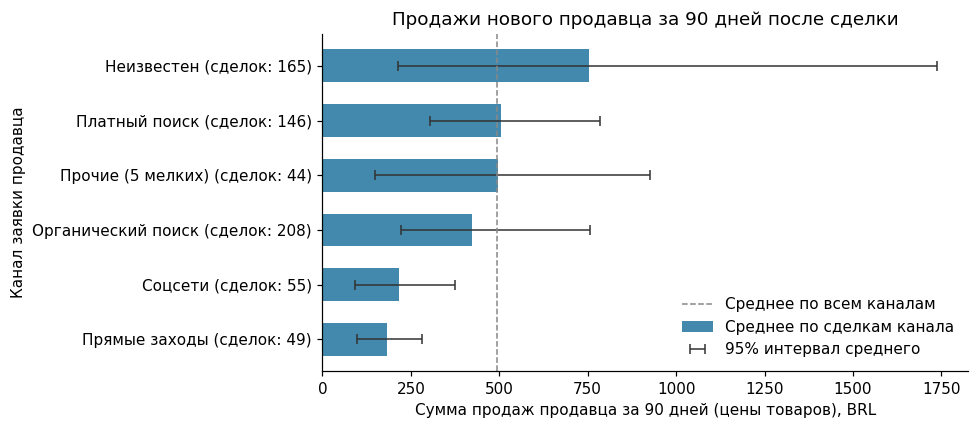

In [24]:
plot_gmv = channel_gmv.drop('Все каналы').sort_values('gmv90')
y = range(len(plot_gmv))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(y, plot_gmv.gmv90, color='#4388ad', height=0.6, label='Среднее по сделкам канала')
ax.errorbar(plot_gmv.gmv90, y, xerr=[plot_gmv.gmv90 - plot_gmv.ci_low, plot_gmv.ci_high - plot_gmv.gmv90],
            fmt='none', ecolor='#333333', capsize=3, linewidth=1, label='95% интервал среднего')
ax.axvline(channel_gmv.loc['Все каналы', 'gmv90'], color='#888888', linestyle='--', linewidth=1,
           label='Среднее по всем каналам')
ax.set_yticks(y, [f'{name} (сделок: {n})' for name, n in plot_gmv.deals.items()])
ax.set(title='Продажи нового продавца за 90 дней после сделки',
       xlabel='Сумма продаж продавца за 90 дней (цены товаров), BRL', ylabel='Канал заявки продавца')
ax.legend(loc='lower right', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

**Результат:** интервалы большинства каналов пересекаются; уверенно ниже среднего только «Соцсети» и «Прямые заходы». Высокое среднее у «Неизвестен» создает один крупный продавец.

**Вывод:** допустимая цена заявки в среднем 2.59 BRL — для отдела продаж нереально мало, но оценка занижена: 462 из 842 продавцов не найдены в данных заказов, горизонт — 90 дней, подписка не учтена. Поэтому абсолютное значение LTV/CAC не используем как порог окупаемости, а сравниваем каналы.

**Решение:** бюджет на заявки из соцсетей пересматривать первым: при той же цене заявки они окупаются в 4–5 раз хуже поиска.

### 6.6 DAU, WAU и MAU

*Гайсин М. В.*

Активный покупатель за период — покупатель хотя бы с одним учитываемым заказом в этом периоде (3.1): заказ `delivered`, дата — дата оформления, окно — январь 2017 — август 2018. DAU и WAU — средние за месяц значения по дням и по полным неделям, MAU — число активных покупателей за месяц. Новые — покупатели, у которых в этом месяце первая покупка (когорты из 6.1).

In [25]:
# Активный покупатель за период — хотя бы один учитываемый заказ в нем (3.1)
buyer_days = analysis_orders[['customer_unique_id', 'purchase_date']].drop_duplicates()
all_days = pd.date_range(ANALYSIS_START, LAST_OBSERVED_DAY)
dau = buyer_days.groupby('purchase_date').customer_unique_id.nunique().reindex(all_days, fill_value=0)
wau = buyer_days.groupby(buyer_days.purchase_date.dt.to_period('W-SUN')).customer_unique_id.nunique()
wau = wau[(wau.index.start_time >= ANALYSIS_START) & (wau.index.end_time < ANALYSIS_END)]  # только полные недели
mau = buyer_days.groupby(buyer_days.purchase_date.dt.to_period('M')).customer_unique_id.nunique()

audience = pd.DataFrame({
    'dau': dau.groupby(dau.index.to_period('M')).mean(),
    'wau': wau.groupby(wau.index.start_time.to_period('M')).mean(),  # неделя — в месяце своего понедельника
    'mau': mau,
    'new': cohort_sizes,
})
audience['dau_mau'] = audience.dau / audience.mau * 100
audience['new_share'] = audience.new / audience.mau * 100
assert audience.new.le(audience.mau).all()

audience_table = audience[['dau', 'wau', 'mau', 'dau_mau', 'new_share']].round(1)
audience_table[['wau', 'mau']] = audience_table[['wau', 'mau']].round(0).astype(int)
audience_table.index.name = 'Месяц'
display(audience_table.rename(columns={
    'dau': 'DAU (среднее)', 'wau': 'WAU (среднее)', 'mau': 'MAU',
    'dau_mau': 'DAU/MAU, %', 'new_share': 'Новых в MAU, %'}))

,DAU (среднее),WAU (среднее),MAU,"DAU/MAU, %","Новых в MAU, %"
Месяц,,,,,
2017-01,23.2,208,718,3.2,99.9
2017-02,58.5,419,1630,3.6,99.9
2017-03,81.1,570,2508,3.2,99.8
2017-04,76.0,538,2274,3.3,99.2
2017-05,112.9,785,3479,3.2,99.2
2017-06,102.9,709,3076,3.3,98.7
2017-07,123.2,888,3802,3.2,98.7
2017-08,133.3,924,4114,3.2,98.6
2017-09,136.8,962,4083,3.4,98.1


**Результат:** MAU вырос с 718 в январе 2017 до 6–7 тыс. в 2018 году, DAU — с 23 до 198–230 в день. DAU/MAU около 3%: покупатель активен в среднем один день в месяц. 97–99% MAU каждого месяца — новые покупатели, что совпадает с низким retention в 6.1.

**Решение:** рост аудитории определяется привлечением новых покупателей. DAU/MAU для такого продукта не показывает вовлеченность, поэтому возврат покупателей отслеживаем по retention, а не по DAU/MAU.

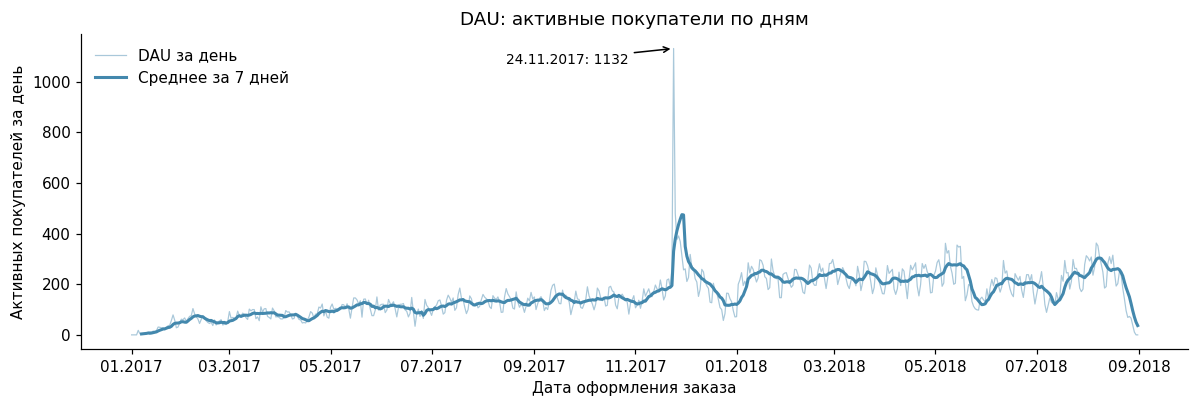

Средний DAU в 2018 году по дням недели (пн–вс): [249, 242, 242, 227, 198, 165, 184]


In [26]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(dau.index, dau, color='#a9c8da', linewidth=0.8, label='DAU за день')
ax.plot(dau.index, dau.rolling(7).mean(), color='#4388ad', linewidth=2, label='Среднее за 7 дней')
peak_day = dau.idxmax()
ax.annotate(f'{peak_day:%d.%m.%Y}: {dau.max()}', xy=(peak_day, dau.max()), xytext=(-110, -10),
            textcoords='offset points', fontsize=9, arrowprops={'arrowstyle': '->'})
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m.%Y'))
ax.set(title='DAU: активные покупатели по дням', xlabel='Дата оформления заказа',
       ylabel='Активных покупателей за день')
ax.legend(loc='upper left', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

weekday_dau = dau['2018'].groupby(dau['2018'].index.day_of_week).mean()
print('Средний DAU в 2018 году по дням недели (пн–вс):', weekday_dau.round(0).astype(int).tolist())

**Результат:** в 2018 году DAU держится на уровне 198–230 в день и к лету немного снижается. Пик — 24.11.2017, 1 132 покупателя, вероятно, из-за Black Friday. В понедельник покупателей в среднем 249, в субботу — 165, на треть меньше. Падение почти до нуля в последние дни августа 2018 — обрыв выгрузки (2.3), а не уход покупателей.

## 7. Этика

Перед чек-листом проверяем, какие персональные и чувствительные данные есть в датасете. На эти цифры опираются пункты 7.3 и 7.4.

In [27]:
reviews = raw['reviews']
review_text = pd.concat([reviews.review_comment_title, reviews.review_comment_message]).dropna()
PII = {
    'email': r'[\w.+-]+@[\w-]+\.[\w.]+',
    'телефон': r'\(?\b\d{2}\)?[\s.-]?9?\d{4}[\s.-]?\d{4}\b',
    'CPF': r'\b\d{3}\.?\d{3}\.?\d{3}-?\d{2}\b',
    'имя («meu nome é», «me chamo»)': r'(?i:\bmeu nome (?:é|e)\b|\bme chamo\b)',
}
display(pd.Series({k: int(review_text.str.contains(p).sum()) for k, p in PII.items()},
                  name='Отзывов с совпадением').to_frame())

zip_sizes = customers.drop_duplicates('customer_unique_id').customer_zip_code_prefix.value_counts()
print(f'Покупателей в префиксах индекса, где их меньше пяти: {zip_sizes[zip_sizes < 5].sum() / zip_sizes.sum():.1%}')

SENSITIVE = {'beleza_saude': 'здоровье', 'fraldas_higiene': 'здоровье', 'bebes': 'дети',
             'fashion_roupa_infanto_juvenil': 'дети', 'brinquedos': 'дети'}
bought = (items[['order_id', 'product_id']]
          .merge(products[['product_id', 'product_category_name']], on='product_id')
          .merge(order_customers[['order_id', 'customer_unique_id']], on='order_id'))
bought['group'] = bought.product_category_name.map(SENSITIVE)
share = bought.groupby('group').customer_unique_id.nunique() / bought.customer_unique_id.nunique()
display(share.mul(100).round(1).rename('% покупателей').to_frame())
print(f'Сделок с заполненным lead_behaviour_profile: {deals.lead_behaviour_profile.notna().mean():.0%}')

,Отзывов с совпадением
email,0
телефон,3
CPF,1
"имя («meu nome é», «me chamo»)",1


Покупателей в префиксах индекса, где их меньше пяти: 19.0%


,% покупателей
group,
дети,7.0
здоровье,9.1


Сделок с заполненным lead_behaviour_profile: 79%


В отзывах покупатели сами оставили три телефона, номер, похожий на CPF, и одно полное имя. Email-адресов нет. Olist заменил ID хешами, а названия магазинов в отзывах заменил на «дома» из «Игры престолов», но свободный текст очищен не до конца.

19 % покупателей живут в префиксах индекса, где покупателей меньше пяти. Вместе с датой заказа и городом это сильно сужает круг людей.

Специальных категорий среди полей нет, но по покупкам можно догадаться о здоровье человека (9,1 % покупателей) и о том, есть ли у него дети (7,0 %). У 79 % сделок с продавцами заполнен `lead_behaviour_profile`: психотип контактного лица, который поставил менеджер по продажам.


### 7.1 Цель

Мы строим систему продуктовой аналитики Olist как площадки, где встречаются покупатели и продавцы, и развиваем ее на всех этапах проекта. В этой сдаче это описание продукта, метрики, определения, трекинг, retention и LTV/CAC (разделы 1-6). Дальше на тех же данных будут сегментация покупателей и продавцов, оценка экспериментов и прогнозы. Каждый расчет нужен для конкретного продуктового решения: какие инициативы брать в работу, в какие каналы привлекать продавцов, как удерживать покупателей.

Данные используются только для этой цели. Выводы делаем по группам (когорта, месяц, канал лида, штат), а не по отдельным людям, и не пытаемся узнать, кто стоит за ID. Если появится задача на уровне отдельного покупателя, например модель оттока, чек-лист проходим заново до начала работы.

События из разд. 5 собираются только под метрики из разд. 4, лишних полей в них нет. Текст отзыва не нужен ни одной метрике, поэтому в `review_submitted` передается только оценка.

**Риск:** при разборе гипотез захочется смотреть на конкретного покупателя, например выяснять, почему он ушел.

**Мера:** в ноутбуке нет выводов по отдельным `customer_unique_id` и `seller_id`, кроме проверок качества данных.

### 7.2 Согласие

Мы не собирали эти данные и не можем спросить согласия у покупателей и продавцов. Olist сам опубликовал датасет в обезличенном виде под открытой лицензией, и мы используем его только для анализа. С людьми из данных мы не связываемся, ID не деанонимизируем и не объединяем датасет с внешними источниками вроде соцсетей или адресных баз.

Если запускать трекинг из разд. 5 в продукте, основания для обработки данных будут разными (LGPD, бразильский закон о персональных данных, ст. 7):

| Данные | События или поля | Основание | Что нужно |
|---|---|---|---|
| Заказ | `order_placed`, `order_delivered`, `order_canceled` | исполнение договора | упомянуть в политике конфиденциальности |
| Отзыв | `review_submitted` | законный интерес | предупредить, что отзыв публикуется и анализируется |
| Заявка продавца | `lead_created`, `deal_won` | действия до заключения договора | уведомление в форме заявки |
| Рассылки и промокоды из разд. 4.3 | отдельного события нет | согласие | отдельная галочка и отписка в каждом письме |
| Психотип продавца | `lead_behaviour_profile` | нет | без явного согласия не собирать |

**Риск:** рассылки для повторных покупок (разд. 4.3) могут уйти людям, которые не соглашались на маркетинг.

**Мера:** в эксперименты по удержанию попадают только покупатели, давшие согласие на рассылки.

### 7.3 Специальные категории данных

К специальным категориям LGPD (ст. 5) и 152-ФЗ (ст. 10) относят расу и национальность, религию, политические взгляды, здоровье, интимную жизнь, генетические и биометрические данные. Прямо в датасете их нет, это видно по списку полей в разд. 2. Косвенно они появляются в трех местах:
- по покупкам в категориях здоровья и детских товаров можно догадаться о здоровье человека и о том, есть ли у него дети;
- в отзывах люди пишут что угодно, в том числе о болезни или беременности;
- `lead_behaviour_profile` по закону не относится к специальным категориям, но это оценка личности, которую менеджер поставил без ведома человека.

**Мера:** категории товаров используем только в агрегатах (выручка и доля заказов по категории) и не делим по ним покупателей на сегменты. Текст отзывов в расчетах не участвует. `lead_behaviour_profile` не используется в метриках и сегментации, каналы лидов в разд. 4.4 сравниваются по `origin`.

### 7.4 Передача третьим лицам

Датасет лежит в командном репозитории (разд. 9). Лицензия CC BY-NC-SA 4.0 разрешает распространять копию с указанием авторства и под той же лицензией, это сделано в `README.md`. Строки с ID и текстом отзывов не загружаем во внешние сервисы аналитики. Если такой сервис нужен, передаем ему код или агрегаты.

В отчет, презентацию и README попадают только агрегаты. Группы меньше пяти человек не показываем или объединяем с соседними, так закрываются малые префиксы индексов и маленькие когорты.

**Риск:** в публичном репозитории лежат исходные отзывы с телефонами и именем покупателя.

**Мера:** файлы датасета не меняем, чтобы они совпадали с версией на Kaggle, но текст отзывов в ноутбуке не выводится и в производные файлы не попадает.

### 7.5 Хранение и удаление

| Что | Где | Сколько храним | Как удаляем |
|---|---|---|---|
| Исходный датасет | `data/` в репозитории | до конца курса | удалить папку и при необходимости переписать историю git (`git filter-repo`) |
| Промежуточные таблицы с ID | `data/interim/`, исключена в `.gitignore` | пока идет расчет | вручную, в git они не попадают |
| Агрегаты и графики | ноутбук и отчет | вместе с проектом | вместе с репозиторием |
| Локальные копии | компьютеры участников | до защиты | каждый удаляет у себя |

Если Olist уберет датасет с Kaggle или сменит лицензию, а также если человек узнает себя в данных и попросит удалить запись, удаляем данные из репозитория и пересчитываем результаты.

### 7.6 Лицензия и происхождение датасета

| Вопрос | Ответ |
|---|---|
| Источник | Olist, бразильская e-commerce-платформа. Данные компания сама опубликовала на Kaggle |
| Наборы и версии | *Brazilian E-Commerce Public Dataset by Olist* (v2) и *Marketing Funnel by Olist* (v2), скачаны 25.10.2026 |
| Происхождение | реальные данные Olist: около 100 тыс. заказов за 2016-2018 годы и 8 000 заявок продавцов за 2017-2018 годы. Это выборка, а не все заказы компании |
| Обезличивание | ID заменены хешами, названия магазинов в отзывах заменены на «дома» из «Игры престолов», от адреса остался префикс индекса. Текст отзывов очищен не полностью (см. проверку выше) |
| Лицензия | CC BY-NC-SA 4.0 |
| BY: указать авторство | ссылки и версии есть в `README.md` и `data/README.md` |
| NC: только некоммерческое использование | проект учебный, результаты не используются в коммерческих целях |
| SA: та же лицензия | проект распространяется под CC BY-NC-SA 4.0 (`LICENSE.md`) |
| Указать изменения | в README перечислены очистка, фильтрация тестовых записей, объединение по `seller_id` и исключение `olist_geolocation_dataset.csv` |
| Отказ от одобрения | в README указано «No endorsement by Olist is implied» |

Лицензия регулирует права на саму базу данных. Обязанности по защите персональных данных она не снимает, поэтому пункты 7.1-7.5 выполняются и при соблюдении лицензии.

### 7.7 Итог: чек-лист

| Пункт | Риск | Мера |
|---|---|---|
| Цель | выводы об отдельных людях | только агрегаты, без разбора отдельных ID |
| Согласие | рассылки без согласия | рассылки только по согласию, без деанонимизации и внешних данных |
| Специальные категории | здоровье и дети по покупкам, текст отзывов, психотип продавца | категории только в агрегатах, текст отзывов и `lead_behaviour_profile` не используются |
| Передача третьим лицам | телефоны и имя из отзывов в репозитории и выводах | текст отзывов не выводится, в отчетах только группы от пяти человек |
| Хранение и удаление | копии хранятся без срока | сроки и способ удаления в 7.5, `data/interim/` в `.gitignore` |
| Лицензия и происхождение | нарушение условий BY, NC, SA | авторство указано, использование некоммерческое, лицензия та же, изменения перечислены |

## 8. Критерии успеха

Цели заданы для трех ключевых метрик пирамиды и для одного ограничения по риск-метрике.

### 8.1 Целевые значения

| Метрика | Роль | База | Цель к финалу | Обоснование цели |
|---|---|---|---|---|
| Успешные сделки в месяц | North Star | Среднее за март–август 2018 (шесть последних полных месяцев окна); значение в таблице 8.3 | +10% к базе | MAU держится на 6–7 тыс. и на 97–99% состоит из новых покупателей (6.6). Рост должен идти за счет доли успешных заказов и повторных покупок, а не только привлечения |
| Повторные покупки за 90 дней | Диагностическая | 1.30% (R90, 17 когорт, 75 123 покупателя; 6.2) | не ниже 1.8% (+0.5 п.п.) | 1.8% - уровень лучшей наблюдавшейся когорты (сентябрь 2017: 1.82%), цель лежит в уже встречавшемся диапазоне |
| Активация продавцов за 90 дней | Диагностическая | 43.2% (667 сделок с полными 90 днями; 6.5) | не ниже 50% (+6.8 п.п.) | Для цели примерно каждый восьмой продавец из не начавших продавать должен получить первый заказ за 90 дней |
| Доля отмененных заказов | Риск-метрика (ограничение) | Доля за март–август 2018; значение в таблице 8.3 | не выше базы более чем на 0.5 п.п. | Рост успешных сделок не должен достигаться за счет сорванных (4.5) |

### 8.2 Способ проверки

1. **Расчет.** Каждая метрика считается по формуле и определениям: заказы `delivered`, окно 01.01.2017–31.08.2018, активность датируется созданием заказа. База считается тем же кодом, что и текущее значение: R90 - `common_horizon_summary`, активация - `seller_deals.activated`, North Star и доля отмен.
2. **Сравнение.** Для когортных метрик берутся только когорты с полным горизонтом наблюдения; доля считается как сумма вернувшихся, деленная на сумму покупателей, а не как среднее процентов.
3. **Причинный эффект.** Эффект изменения продукта проверяется A/B-тестом: группы формируются случайно на уровне покупателя (для активации - на уровне сделки), метрики и горизонты те же. Доли сравниваются z-критерием для двух долей, средние - бутстрап-интервалом. Цель считается достигнутой, если значение в тестовой группе не ниже целевого, отличие от контроля значимо на уровне 5% и ограничение по риск-метрике не нарушено.
4. **Ограничение по риску.** Если доля отмененных заказов превышает порог, изменение не внедряется, даже если ключевые метрики достигли целей.

**Ограничения.** Данные заканчиваются в августе 2018 года, поэтому достижение целей на них не наблюдается: на текущих данных проверяются базовые значения и формулы. База активации - нижняя оценка: продавцы, не найденные в данных заказов (462 из 842 сделок), считаются не начавшими продавать. Конверсия по каналам и LTV продавцов опираются на допущение о комиссии 15%.

### 8.3 Базовые значения и целевые пороги

North Star и доля отмен считаются по формулам раздела 4.1. Для заказов с несколькими отзывами берется последний по дате создания.


## 9. Репозиторий

Репозиторий команды: https://github.com/iverid/ProdAnal. Ноутбук лежит в его корне.

| Файл или папка | Содержимое |
|---|---|
| `project.ipynb` | этот ноутбук |
| `data/` | исходные CSV обоих датасетов без изменений: папки `Olist E-Commerce Public Dataset/` и `Marketing Funnel by Olist/` (версия 2, скачаны 25.10.2026) |
| `README.md`, `README.ru.md` | описание задачи, шаги воспроизведения, источники данных, результаты, вклад команды (English / русский) |
| `requirements.txt` | версии библиотек |
| `.gitignore` | исключает служебные файлы Python и Jupyter |
| `LICENSE.md` | текст лицензии CC BY-NC-SA 4.0 |

**Как запустить.** Установить зависимости (`pip install -r requirements.txt`), открыть ноутбук из корня репозитория и выполнить все ячейки (Restart & Run All). Пути относительные: данные читаются из `data/`, абсолютных путей нет.

**Откуда данные.** Brazilian E-Commerce Public Dataset by Olist и Marketing Funnel by Olist (Kaggle, версия 2, CC BY-NC-SA 4.0); ссылки и условия использования - в разделе 2.1 и README. Файл `olist_geolocation_dataset.csv` исключен как не относящийся к задаче.

**Что получилось.**
- Повторные покупки редки: за 90 дней возвращается 1.30% новых покупателей, за 180 дней - 1.99% (6.2).
- За 90 дней после сделки начинают продавать 43.2% продавцов; при допущении о комиссии 15% LTV90 сделки - 74 BRL, допустимый CAC при LTV/CAC = 3 - 25 BRL (6.5).
- MAU держится на 6–7 тыс. покупателей, 97–99% из них новые; DAU/MAU около 3% (6.6).
- Критерии успеха зафиксированы в разделе 8.
